---

# Exploratory Data Analysis: Pembatalan Pesanan Ronaldo Hotel

*Analisis data untuk Tugas Besar 2 IF3170 Inteligensi Artifisial, sebagai dasar perancangan preprocessing dan model SVM.*

---

## Kelompok G04: TreeIsAllYouNeed

- IF3170 Inteligensi Artifisial 2026/2027

---

## Daftar Isi

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Struktur dan Kualitas Data**](#3)
4. [**Distribusi Target**](#4)
5. [**Fitur terhadap Target**](#5)
6. [**Pola Waktu**](#6)
7. [**Relevansi dan Redundansi Fitur**](#7)
8. [**Perbandingan Train dan Test**](#8)
9. [**Implikasi untuk SVM**](#9)
10. [**Kesimpulan dan Rekomendasi**](#10)


---

# Introduction <a name="1"></a>

---

## Overview

*Ronaldo Hotel membutuhkan sistem yang mengestimasi pengunjung yang akan membatalkan pesanan. Estimasi ini membantu pengelolaan kapasitas kamar tanpa sumber daya komputasi sebesar deep learning.*

## Aim

*Notebook ini memahami struktur, kualitas, dan pola data sebelum SVM dibangun. Keluarannya adalah daftar keputusan preprocessing yang didukung bukti, serta arahan pemilihan kernel dan ukuran data latih untuk SVM from scratch.*

## Metric

***Macro F1-score** adalah metrik resmi kompetisi, yaitu rata-rata F1 kelas batal dan kelas tidak batal. Kedua kelas berbobot sama, sehingga model yang hanya memprediksi satu kelas mendapat skor rendah walaupun akurasinya tinggi.*

$$\text{Macro F1} = \frac{F_1^{(0)} + F_1^{(1)}}{2}, \qquad F_1^{(c)} = \frac{2 \cdot \text{Precision}^{(c)} \cdot \text{Recall}^{(c)}}{\text{Precision}^{(c)} + \text{Recall}^{(c)}}$$

***ROC-AUC** ikut dilaporkan untuk menilai kualitas peringkat skor tanpa bergantung pada threshold. Leaderboard publik memakai sekitar 30% data test dan peringkat akhir memakai 70% sisanya, sehingga keputusan model didasarkan pada validasi silang, bukan skor publik.*

## Dataset

*Data berasal dari kompetisi Kaggle Tugas Besar 2 IF3170 pada tautan: https://www.kaggle.com/competitions/T2-IF3170-2026-2027*

*Dataset terdiri atas 27.373 baris latih berlabel dan 6.844 baris uji tanpa label. Deskripsi di bawah disimpulkan dari nama kolom dan perlu dicocokkan dengan deskripsi resmi di halaman kompetisi.*

*Dataset digunakan untuk memprediksi status pembatalan setiap pesanan.*

**Attributes**

1.  `id`                        : Identitas unik pesanan, bukan fitur
2.  `num_adults`                : Jumlah tamu dewasa
3.  `num_children`              : Jumlah tamu anak
4.  `weekend_nights`            : Jumlah malam akhir pekan
5.  `weekday_nights`            : Jumlah malam hari kerja
6.  `meal_package`              : Paket makan
7.  `needs_parking`             : Kebutuhan parkir (0 atau 1)
8.  `room_category`             : Kategori kamar (Type A sampai Type G)
9.  `days_before_arrival`       : Jarak hari antara pemesanan dan kedatangan
10. `arrival_year`              : Tahun kedatangan
11. `arrival_month`             : Bulan kedatangan
12. `arrival_day`               : Tanggal kedatangan
13. `booking_channel`           : Kanal pemesanan
14. `is_returning_guest`        : Status tamu lama (0 atau 1)
15. `prior_cancellations`       : Jumlah pembatalan sebelumnya
16. `prior_completed_bookings`  : Jumlah pesanan selesai sebelumnya
17. `nightly_rate_idr`          : Tarif per malam dalam rupiah
18. `special_requests`          : Jumlah permintaan khusus

**Target**
 `is_canceled`  : Status pembatalan (0: Tidak batal, 1: Batal)

## Approach: EDA Terarah untuk SVM

*EDA ini tidak berhenti pada deskripsi statistik. Setiap temuan diterjemahkan menjadi keputusan bagi SVM, yang sensitif terhadap skala fitur, bergantung pada encoding numerik, dan memiliki biaya latih yang tumbuh cepat terhadap jumlah data.*

```
Kualitas data (missing, duplikat, anomali)
    |
    +-- Pola fitur dan waktu terhadap target
         |
    Perbandingan train dan test (tanpa penggabungan)
         |
    Uji cepat SVM -> kernel, skala, ukuran data latih
```

*Train dan test tidak pernah digabung. Pada uji cepat, seluruh imputasi, encoding, dan scaling berada di dalam pipeline sehingga hanya dipelajari dari fold latih.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook ini berjalan pada CPU dan tidak memerlukan GPU. Dependensi tercatat pada `requirements.txt` di root repository dan dipasang dengan `uv pip install -r requirements.txt` di dalam `.venv`.

## Import Libraries

In [1]:
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVC

## Seed Everything

In [2]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(42)

## Settings

Seluruh path, kelompok kolom, dan parameter uji dipusatkan di sini. Perpindahan antara Kaggle dan lokal tidak memerlukan perubahan di luar kelas ini.

In [3]:
class Settings:
    SEED         = 42
    _KAGGLE_HITS = sorted(Path('/kaggle/input').glob('**/train.csv'))

    DATA_DIR   = _KAGGLE_HITS[0].parent if _KAGGLE_HITS else Path('dataset')
    OUTPUT_DIR = Path('/kaggle/working') if _KAGGLE_HITS else Path('../../output')
    FIG_DIR    = OUTPUT_DIR / 'eda'

    ID_COL     = 'id'
    TARGET     = 'is_canceled'
    CAT_COLS   = ['meal_package', 'room_category', 'booking_channel']
    BIN_COLS   = ['needs_parking', 'is_returning_guest']
    COUNT_COLS = [
        'num_adults', 'num_children', 'weekend_nights', 'weekday_nights',
        'prior_cancellations', 'prior_completed_bookings', 'special_requests',
    ]
    CONT_COLS  = ['days_before_arrival', 'nightly_rate_idr']
    DATE_COLS  = ['arrival_year', 'arrival_month', 'arrival_day']
    NUM_COLS   = COUNT_COLS + CONT_COLS + BIN_COLS + DATE_COLS
    FEATURES   = NUM_COLS + CAT_COLS

    PROBE_SAMPLE = 6000
    PROBE_FOLDS  = 3
    SAMPLE_SIZES = [1000, 2000, 4000, 8000, 16000]
    HOLDOUT_SIZE = 0.2

    NEG_COLOR = '#2a78d6'
    POS_COLOR = '#eb6834'
    MID_COLOR = '#e8e7e3'
    SURFACE   = '#fcfcfb'
    INK       = '#0b0b0b'
    MUTED     = '#52514e'

CFG = Settings()
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.facecolor': CFG.SURFACE, 'axes.facecolor': CFG.SURFACE,
    'savefig.facecolor': CFG.SURFACE, 'figure.dpi': 110,
    'axes.edgecolor': CFG.MUTED, 'axes.labelcolor': CFG.MUTED,
    'axes.titlecolor': CFG.INK, 'axes.titlesize': 11, 'axes.labelsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': CFG.MID_COLOR, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'xtick.color': CFG.MUTED, 'ytick.color': CFG.MUTED,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.frameon': False,
    'legend.fontsize': 8, 'font.size': 9,
})
pd.set_option('display.max_columns', 50, 'display.width', 160)

DIVERGING = LinearSegmentedColormap.from_list(
    'blue_gray_orange', [CFG.NEG_COLOR, CFG.MID_COLOR, CFG.POS_COLOR]
)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    'orange_ramp', [CFG.SURFACE, CFG.POS_COLOR, '#8a3312']
)

def save_fig(name: str):
    plt.tight_layout()
    plt.savefig(CFG.FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

## Load Dataset

Berkas dibaca sebagai dua objek terpisah. Keduanya tidak digabung di bagian mana pun.

In [4]:
train = pd.read_csv(CFG.DATA_DIR / 'train.csv')
test  = pd.read_csv(CFG.DATA_DIR / 'test.csv')

assert not set(train[CFG.ID_COL]) & set(test[CFG.ID_COL])
assert train[CFG.ID_COL].is_unique and test[CFG.ID_COL].is_unique
assert set(train.columns) - set(test.columns) == {CFG.TARGET}

print(f'Train: {train.shape}  Test: {test.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Struktur dan Kualitas Data <a name="3"></a>

---

Bagian ini memeriksa tipe kolom, nilai hilang, duplikat, dan nilai yang tidak wajar. Hasilnya menentukan langkah cleaning, yang pada SVM wajib tuntas karena model tidak dapat menerima nilai kosong.

## Skema Kolom

Ringkasan tipe, kardinalitas, dan rentang setiap fitur memperlihatkan kolom yang perlu encoding serta perbedaan skala antarfitur.

In [5]:
schema = pd.DataFrame({
    'dtype': train[CFG.FEATURES].dtypes.astype(str),
    'n_unique': train[CFG.FEATURES].nunique(),
    'missing_pct': (train[CFG.FEATURES].isna().mean() * 100).round(2),
    'min': train[CFG.NUM_COLS].min(),
    'median': train[CFG.NUM_COLS].median(),
    'max': train[CFG.NUM_COLS].max(),
}).loc[CFG.FEATURES]
schema

,dtype,n_unique,missing_pct,min,median,max
num_adults,float64,5,2.96,0.0,2.0,4.0
num_children,float64,6,11.09,0.0,0.0,10.0
weekend_nights,int64,8,0.00,0.0,1.0,7.0
weekday_nights,int64,18,0.00,0.0,2.0,17.0
prior_cancellations,int64,9,0.00,0.0,0.0,13.0
prior_completed_bookings,int64,52,0.00,0.0,0.0,58.0
special_requests,float64,6,9.13,0.0,0.0,5.0
days_before_arrival,float64,407,4.10,0.0,58.0,448.0
nightly_rate_idr,float64,2787,7.45,0.0,1644000.0,9165000.0
needs_parking,float64,2,3.95,0.0,0.0,1.0


#### Insights

> Data memuat 17 fitur, terdiri atas 14 numerik dan 3 kategorikal. Kolom hitungan bertipe float karena mengandung nilai kosong. Rentang fitur sangat timpang, dari 0-1 pada fitur biner hingga 9,165 juta pada `nightly_rate_idr`.

## Nilai Hilang

Persentase nilai hilang dibandingkan antara train dan test untuk melihat apakah pola kekosongan sama pada kedua berkas.

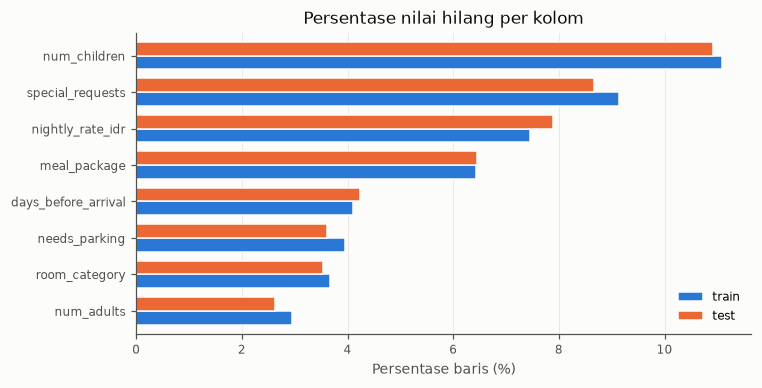

Jumlah kolom kosong per baris:
0    16636
1     8478
2     1933
3      301
4       23
5        2
Baris lengkap: 60.8%


In [6]:
missing = pd.DataFrame({
    'train': train[CFG.FEATURES].isna().mean() * 100,
    'test': test[CFG.FEATURES].isna().mean() * 100,
})
missing = missing[missing['train'] > 0].sort_values('train')

ax = missing.plot.barh(
    figsize=(7, 3.6), width=0.75, color=[CFG.NEG_COLOR, CFG.POS_COLOR], edgecolor=CFG.SURFACE
)
ax.set_title('Persentase nilai hilang per kolom')
ax.set_xlabel('Persentase baris (%)')
ax.grid(axis='y', visible=False)
save_fig('missing_pct')

row_missing = train[CFG.FEATURES].isna().sum(axis=1).value_counts().sort_index()
print('Jumlah kolom kosong per baris:')
print(row_missing.to_string())
print(f'Baris lengkap: {row_missing[0] / len(train):.1%}')

Mekanisme kekosongan diuji dengan chi-square antara indikator kosong dan target. Kekosongan yang berkaitan dengan target berarti indikator kosong itu sendiri membawa sinyal, sehingga imputasi saja akan membuang informasi.

In [7]:
rows = []
for col in missing.index:
    is_missing = train[col].isna()
    table = pd.crosstab(is_missing, train[CFG.TARGET])
    rows.append({
        'kolom': col,
        'n_kosong': int(is_missing.sum()),
        'batal_saat_kosong': train.loc[is_missing, CFG.TARGET].mean(),
        'batal_saat_terisi': train.loc[~is_missing, CFG.TARGET].mean(),
        'p_value': stats.chi2_contingency(table)[1],
    })

missing_test = pd.DataFrame(rows).set_index('kolom').sort_values('p_value')
missing_test['signifikan_bonferroni'] = missing_test['p_value'] < 0.05 / len(missing_test)
missing_test.round(4)

,n_kosong,batal_saat_kosong,batal_saat_terisi,p_value,signifikan_bonferroni
kolom,,,,,
special_requests,2500,0.4084,0.3195,0.0000,True
nightly_rate_idr,2038,0.3131,0.3288,0.1511,False
room_category,1002,0.3483,0.3269,0.1663,False
days_before_arrival,1123,0.3117,0.3283,0.2570,False
needs_parking,1082,0.3124,0.3283,0.2895,False
meal_package,1760,0.3193,0.3282,0.4566,False
num_adults,809,0.3350,0.3274,0.6800,False
num_children,3035,0.3282,0.3276,0.9655,False


Kolom yang signifikan ditelusuri lebih jauh per kanal. Bila kekosongan acak, tingkat batal baris kosong setara campuran baris bernilai nol dan positif sesuai proporsinya. Proporsi nol yang tersirat pada baris kosong dapat dihitung dari ketiga tingkat batal tersebut.

In [8]:
sr_missing = train['special_requests'].isna()
by_channel = train.assign(sr_missing=sr_missing).groupby('booking_channel').agg(
    n=('sr_missing', 'size'),
    pct_kosong=('sr_missing', 'mean'),
    pct_nol=('special_requests', lambda s: s.eq(0).sum() / s.notna().sum()),
    batal=(CFG.TARGET, 'mean'),
).round(3)
display(by_channel)

compare = pd.DataFrame({
    'batal_kosong': train[sr_missing].groupby('booking_channel')[CFG.TARGET].mean(),
    'batal_nol': train[train['special_requests'].eq(0)].groupby('booking_channel')[CFG.TARGET].mean(),
    'batal_positif': train[train['special_requests'].gt(0)].groupby('booking_channel')[CFG.TARGET].mean(),
})
compare['pct_nol_terisi'] = by_channel['pct_nol']
compare['pct_nol_tersirat_pada_kosong'] = (
    (compare['batal_kosong'] - compare['batal_positif'])
    / (compare['batal_nol'] - compare['batal_positif'])
)
display(compare.round(3))

lead_bins = pd.qcut(train['days_before_arrival'], 5, duplicates='drop')
print('Persentase special_requests kosong per kuintil lead time:')
print(sr_missing.groupby(lead_bins, observed=True).mean().round(3).to_string())

,n,pct_kosong,pct_nol,batal
booking_channel,,,,
Airline,88,0.102,1.000,0.307
Complimentary,301,0.070,0.393,0.000
Corporate,1513,0.121,0.781,0.115
Offline Agent,7960,0.127,0.799,0.302
Online Travel Agent,17511,0.073,0.366,0.364


,batal_kosong,batal_nol,batal_positif,pct_nol_terisi,pct_nol_tersirat_pada_kosong
booking_channel,,,,,
Airline,0.333,0.304,NaN,1.000,NaN
Complimentary,0.000,0.000,0.000,0.393,NaN
Corporate,0.137,0.135,0.031,0.781,1.018
Offline Agent,0.306,0.315,0.246,0.799,0.878
Online Travel Agent,0.535,0.603,0.204,0.366,0.829


Persentase special_requests kosong per kuintil lead time:
days_before_arrival
(-0.001, 11.0]    0.091
(11.0, 39.0]      0.089
(39.0, 80.0]      0.089
(80.0, 151.0]     0.088
(151.0, 448.0]    0.103


#### Insights

> Delapan kolom memiliki nilai kosong sebesar 2,96% sampai 11,09%, dengan pola yang hampir sama pada test. Hanya 60,8% baris yang lengkap, sehingga menghapus baris akan membuang 39,2% data dan tidak dapat dilakukan pada test. Imputasi wajib dilakukan.

> Hanya `special_requests` yang kekosongannya berkaitan dengan target (batal 40,8% saat kosong dan 32,0% saat terisi). Tujuh kolom lain tidak signifikan setelah koreksi Bonferroni, sehingga imputasi sederhana memadai untuk kolom tersebut.

> Kekosongan `special_requests` condong ke nilai nol. Pada Online Travel Agent, nilai nol hanya 36,6% dari baris terisi, tetapi tingkat batal baris kosong menyiratkan sekitar 82,9% nol. Pola yang sama muncul pada Offline Agent (87,8% terhadap 79,9%). Estimasi ini mengasumsikan tingkat batal per nilai sama pada baris kosong dan terisi. Imputasi dengan median, yaitu 0, sesuai dengan nilai yang paling mungkin, dan penanda kosong dapat ditambahkan.

## Duplikat

Kolom `id` selalu unik, sehingga duplikat diperiksa pada seluruh fitur. Duplikat yang tersebar ke fold berbeda dapat membuat skor validasi terlalu optimistis.

In [9]:
dup_mask   = train.duplicated(subset=CFG.FEATURES, keep=False)
dup_groups = train[dup_mask].groupby(CFG.FEATURES, dropna=False)[CFG.TARGET]
conflicts  = int((dup_groups.nunique() > 1).sum())

train_keys = train[CFG.FEATURES].drop_duplicates()
overlap    = len(test.merge(train_keys, on=CFG.FEATURES, how='inner'))

print(f'Baris dalam grup duplikat : {dup_mask.sum()}')
print(f'Jumlah grup duplikat      : {dup_groups.ngroups}')
print(f'Baris berlebih            : {train.duplicated(subset=CFG.FEATURES).sum()}')
print(f'Grup dengan label berbeda : {conflicts}')
print(f'Duplikat di dalam test    : {test.duplicated(subset=CFG.FEATURES).sum()}')
print(f'Baris test sama dgn train : {overlap}')

Baris dalam grup duplikat : 128
Jumlah grup duplikat      : 62
Baris berlebih            : 66
Grup dengan label berbeda : 2
Duplikat di dalam test    : 3
Baris test sama dgn train : 42


#### Insights

> Terdapat 62 grup duplikat dengan 66 baris berlebih, dan 2 grup memiliki label berbeda. Membuang duplikat identik termasuk labelnya menghapus 64 baris (0,2%), sehingga dampaknya kecil dan aman. Sebanyak 42 baris test memiliki fitur yang sama dengan train, tetapi baris test tetap harus diprediksi dan tidak boleh dihapus.

## Nilai Tidak Wajar

Beberapa kombinasi nilai tampak tidak masuk akal secara bisnis. Setiap aturan dihitung pada train dan test, bersama tingkat batalnya, untuk memutuskan apakah nilai tersebut derau atau justru informatif.

In [10]:
def anomaly_rules(df: pd.DataFrame) -> dict:
    nights = df['weekend_nights'] + df['weekday_nights']
    return {
        'num_adults = 0': df['num_adults'].eq(0),
        'total malam = 0': nights.eq(0),
        'nightly_rate_idr = 0': df['nightly_rate_idr'].eq(0),
        'num_children >= 9': df['num_children'].ge(9),
        'prior_cancellations >= 10': df['prior_cancellations'].ge(10),
        'total malam >= 15': nights.ge(15),
        'tarif > 6 juta': df['nightly_rate_idr'].gt(6_000_000),
    }

train_rules, test_rules = anomaly_rules(train), anomaly_rules(test)
anomalies = pd.DataFrame({
    'n_train': {k: int(m.sum()) for k, m in train_rules.items()},
    'batal_train': {k: train.loc[m, CFG.TARGET].mean() for k, m in train_rules.items()},
    'n_test': {k: int(m.sum()) for k, m in test_rules.items()},
}).round(3)
display(anomalies)

zero_adults = train[train['num_adults'].eq(0)]
print('num_children saat num_adults = 0:')
print(zero_adults['num_children'].value_counts(dropna=False).sort_index().to_string())

zero_rate = train[train['nightly_rate_idr'].eq(0)]
print('\nTarif 0 per kanal:')
print(zero_rate.groupby('booking_channel')[CFG.TARGET].agg(['size', 'mean']).round(3).to_string())

comp = train[train['booking_channel'].eq('Complimentary')]
print('\nDistribusi tarif kanal Complimentary:')
print(comp['nightly_rate_idr'].describe().round(0).to_string())

print('\nMedian tarif per kanal:')
print(train.groupby('booking_channel')['nightly_rate_idr'].median().to_string())

print('\nKonsistensi tamu lama:')
prior = train['prior_cancellations'] + train['prior_completed_bookings']
print(pd.crosstab(train['is_returning_guest'], prior.gt(0)).to_string())

,n_train,batal_train,n_test
num_adults = 0,106,0.302,22
total malam = 0,64,0.031,9
nightly_rate_idr = 0,413,0.007,85
num_children >= 9,3,0.333,0
prior_cancellations >= 10,21,0.095,8
total malam >= 15,55,0.800,12
tarif > 6 juta,3,0.667,0


num_children saat num_adults = 0:
num_children
1.0      1
2.0    100
3.0      4
NaN      1

Tarif 0 per kanal:
                     size   mean
booking_channel                 
Complimentary         267  0.000
Online Travel Agent   146  0.021

Distribusi tarif kanal Complimentary:
count        289.0
mean       37782.0
std       240709.0
min            0.0
25%            0.0
50%            0.0
75%            0.0
max      2863000.0

Median tarif per kanal:
booking_channel
Airline                1603500.0
Complimentary                0.0
Corporate              1286000.0
Offline Agent          1477000.0
Online Travel Agent    1770000.0

Konsistensi tamu lama:
col_0               False  True 
is_returning_guest              
0                   26684      0
1                       0    689


#### Insights

> Sebagian besar nilai yang tampak aneh ternyata informatif dan muncul juga pada test, sehingga tidak dihapus. Tarif nol memiliki tingkat batal 0,7%, total malam nol 3,1%, dan total malam minimal 15 mencapai 80,0%.

> `num_adults = 0` bukan kesalahan data, karena 105 dari 106 baris memiliki anak dan satu sisanya kosong. `is_returning_guest` juga sepenuhnya konsisten dengan riwayat pesanan.

> Median tarif kanal Complimentary adalah 0, sedangkan median keseluruhan 1,644 juta. Imputasi tarif dengan median global akan keliru pada kanal ini, sehingga imputasi per kanal lebih tepat.

> Outlier yang layak dipangkas hanya sedikit, yaitu `num_children` >= 9 dan tarif di atas 6 juta (masing-masing 3 baris, tidak ada pada test).

---

# Distribusi Target <a name="4"></a>

---

Distribusi kelas menentukan baseline dan perlu tidaknya pembobotan kelas pada SVM.

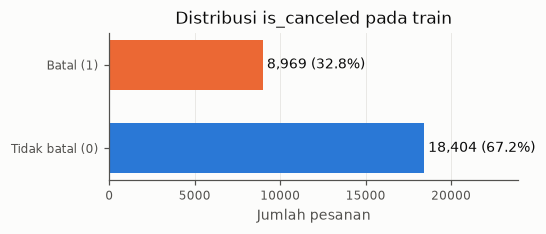

Akurasi baseline kelas mayoritas: 0.6723
Rasio kelas negatif terhadap positif: 2.05
Macro F1 jika semua diprediksi tidak batal: 0.4020
Macro F1 jika semua diprediksi batal: 0.2468


In [11]:
counts = train[CFG.TARGET].value_counts().sort_index()
rates  = counts / counts.sum()

fig, ax = plt.subplots(figsize=(5, 2.2))
labels = ['Tidak batal (0)', 'Batal (1)']
bars = ax.barh(labels, counts.values, color=[CFG.NEG_COLOR, CFG.POS_COLOR], height=0.6)
for bar, n, r in zip(bars, counts.values, rates.values):
    ax.text(bar.get_width() + 250, bar.get_y() + bar.get_height() / 2,
            f'{n:,} ({r:.1%})', va='center', color=CFG.INK)
ax.set_xlim(0, counts.max() * 1.3)
ax.set_title('Distribusi is_canceled pada train')
ax.set_xlabel('Jumlah pesanan')
ax.grid(axis='y', visible=False)
save_fig('target_distribution')

print(f'Akurasi baseline kelas mayoritas: {rates.max():.4f}')
print(f'Rasio kelas negatif terhadap positif: {counts[0] / counts[1]:.2f}')
print(f'Macro F1 jika semua diprediksi tidak batal: {f1_score(train[CFG.TARGET], np.zeros(len(train)), average="macro"):.4f}')
print(f'Macro F1 jika semua diprediksi batal: {f1_score(train[CFG.TARGET], np.ones(len(train)), average="macro"):.4f}')

#### Insights

> Kelas tidak seimbang secara moderat dengan rasio 2,05 banding 1. Memprediksi seluruh pesanan tidak batal menghasilkan akurasi 0,6723 tetapi Macro F1 hanya 0,4020. Baseline inilah yang harus dilampaui, dan akurasi tidak dapat dijadikan acuan.

---

# Fitur terhadap Target <a name="5"></a>

---

Bagian ini melihat bentuk distribusi fitur dan hubungannya dengan target. Bentuk hubungan penting bagi SVM karena hubungan nonlinear tidak tertangkap kernel linear tanpa transformasi fitur.

## Fitur Kontinu

Dua fitur kontinu dibandingkan per kelas. Tingkat batal per desil memperlihatkan bentuk hubungan secara langsung tanpa asumsi linear.

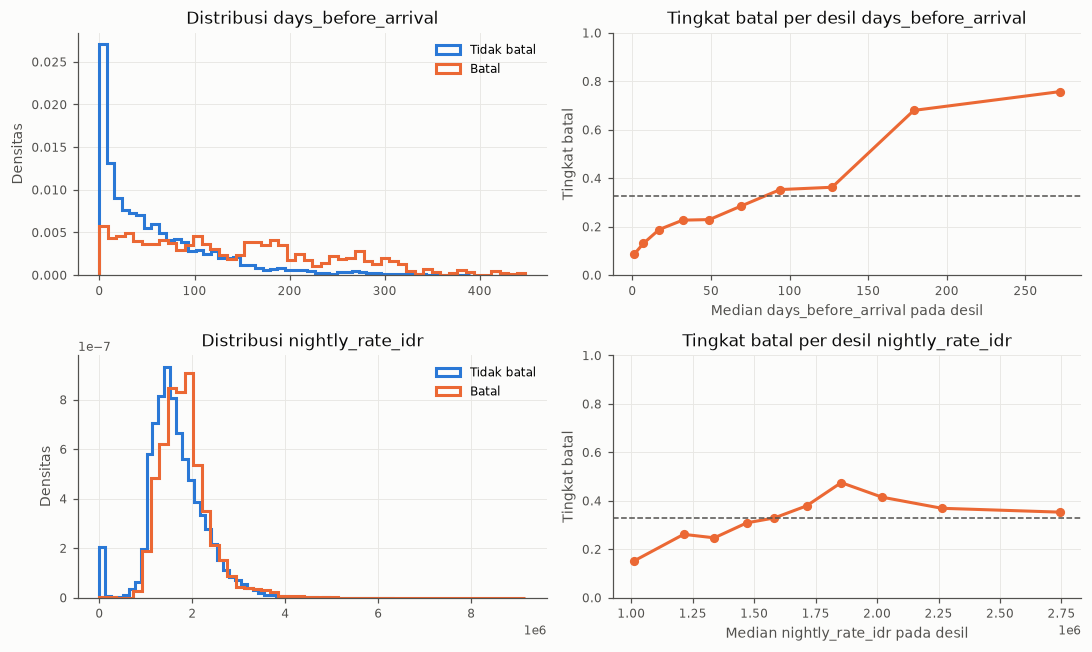

                     size   mean
days_before_arrival             
(-0.001, 4.0]        2922  0.085
(4.0, 11.0]          2371  0.131
(11.0, 24.0]         2664  0.188
(24.0, 39.0]         2672  0.227
(39.0, 58.0]         2583  0.229
(58.0, 80.0]         2617  0.285
(80.0, 108.0]        2552  0.353
(108.0, 151.0]       2639  0.363
(151.0, 213.0]       2624  0.680
(213.0, 448.0]       2606  0.757


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for row, col in zip(axes, CFG.CONT_COLS):
    for value, color, label in [(0, CFG.NEG_COLOR, 'Tidak batal'), (1, CFG.POS_COLOR, 'Batal')]:
        row[0].hist(train.loc[train[CFG.TARGET].eq(value), col].dropna(), bins=50,
                    density=True, histtype='step', linewidth=2, color=color, label=label)
    row[0].set_title(f'Distribusi {col}')
    row[0].set_ylabel('Densitas')
    row[0].legend()

    deciles = pd.qcut(train[col], 10, duplicates='drop')
    curve = train.groupby(deciles, observed=True).agg(
        x=(col, 'median'), rate=(CFG.TARGET, 'mean')
    )
    row[1].plot(curve['x'], curve['rate'], color=CFG.POS_COLOR, linewidth=2, marker='o', markersize=5)
    row[1].axhline(train[CFG.TARGET].mean(), color=CFG.MUTED, linewidth=1, linestyle='--')
    row[1].set_ylim(0, 1)
    row[1].set_title(f'Tingkat batal per desil {col}')
    row[1].set_ylabel('Tingkat batal')
    row[1].set_xlabel(f'Median {col} pada desil')
save_fig('continuous_features')

lead_deciles = pd.qcut(train['days_before_arrival'], 10, duplicates='drop')
print(train.groupby(lead_deciles, observed=True)[CFG.TARGET].agg(['size', 'mean']).round(3).to_string())

#### Insights

> `days_before_arrival` adalah fitur terkuat. Tingkat batal naik dari 8,5% pada desil terendah ke 75,7% pada desil tertinggi, dengan lompatan tajam dari 36,3% ke 68,0% di sekitar 151 hari. Hubungan ini monotonik tetapi tidak linear.

> `nightly_rate_idr` tidak monotonik. Tingkat batal naik sampai puncak 47,5% pada tarif sekitar 1,8 sampai 1,9 juta, lalu turun lagi. Kernel linear tidak dapat menangkap bentuk ini tanpa transformasi fitur. Tarif nol tampak sebagai kelompok terpisah yang hampir selalu tidak batal.

## Fitur Hitungan dan Biner

Fitur hitungan memiliki sedikit nilai unik, sehingga tingkat batal dapat dibaca per nilai. Nilai dengan kurang dari 30 baris ditandai pucat karena estimasinya tidak stabil. Untuk keterbacaan, nilai teratas digabung, yaitu `weekday_nights` >= 10 serta `prior_cancellations` dan `prior_completed_bookings` >= 5.

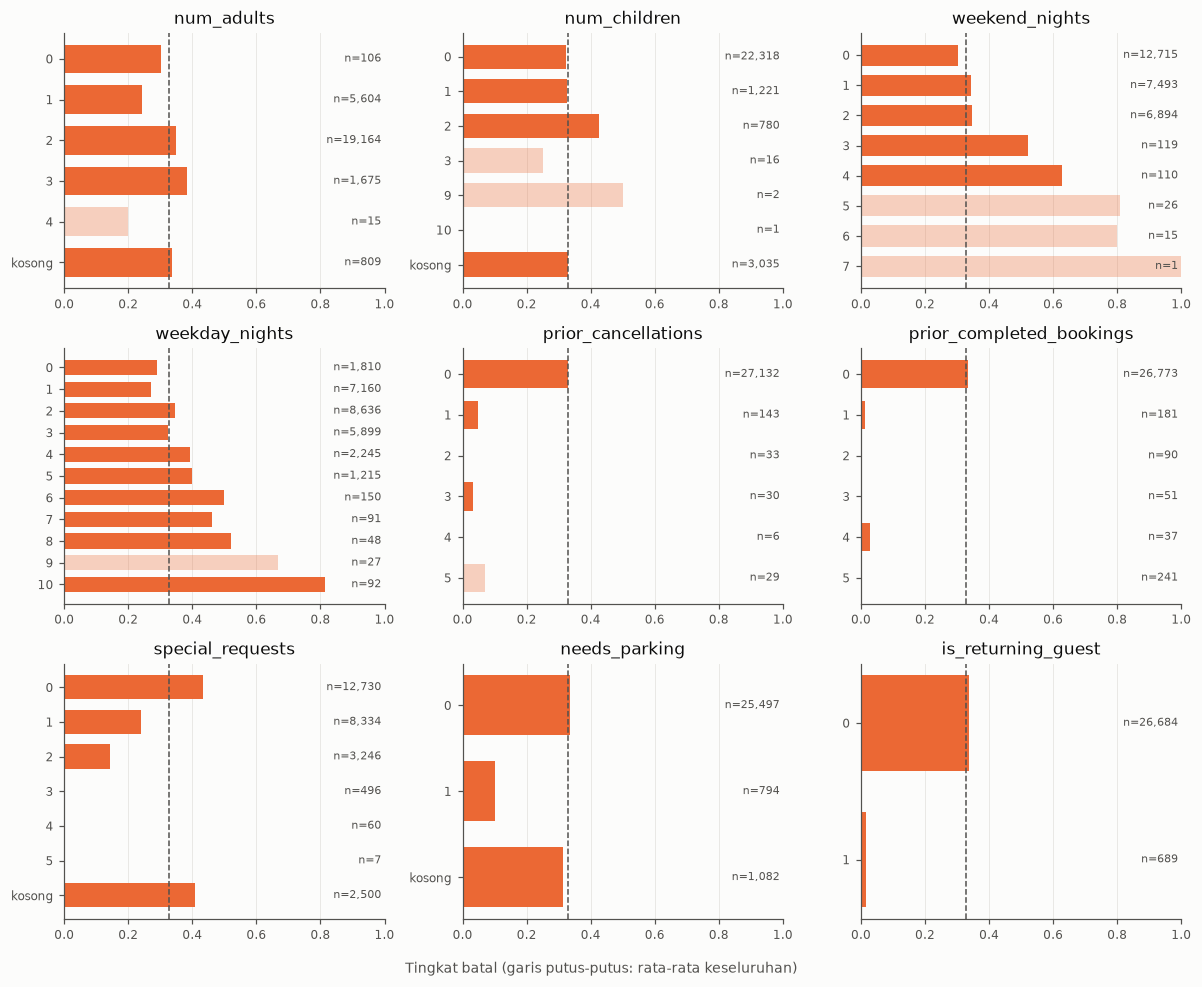

In [13]:
def plot_rate_grid(source, cols, ncols, name, figsize):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    overall = source[CFG.TARGET].mean()
    for ax, col in zip(axes, cols):
        stat = source.groupby(col, dropna=False)[CFG.TARGET].agg(['size', 'mean'])
        labels = [
            'kosong' if pd.isna(v) else (str(int(v)) if isinstance(v, (int, float)) else str(v))
            for v in stat.index
        ]
        alphas = np.where(stat['size'] < 30, 0.3, 1.0)
        colors = [(*plt.matplotlib.colors.to_rgb(CFG.POS_COLOR), a) for a in alphas]
        ax.barh(labels, stat['mean'], color=colors, height=0.7)
        ax.axvline(overall, color=CFG.MUTED, linewidth=1, linestyle='--')
        ax.set_xlim(0, 1)
        ax.set_title(col)
        ax.invert_yaxis()
        ax.grid(axis='y', visible=False)
        for y, n in enumerate(stat['size']):
            ax.text(0.99, y, f'n={n:,}', va='center', ha='right', fontsize=7, color=CFG.MUTED)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    fig.supxlabel('Tingkat batal (garis putus-putus: rata-rata keseluruhan)', fontsize=9, color=CFG.MUTED)
    save_fig(name)

train_view = train.assign(
    weekday_nights=train['weekday_nights'].clip(upper=10),
    prior_cancellations=train['prior_cancellations'].clip(upper=5),
    prior_completed_bookings=train['prior_completed_bookings'].clip(upper=5),
)
plot_rate_grid(train_view, CFG.COUNT_COLS + CFG.BIN_COLS, 3, 'count_binary_rates', (11, 9))

#### Insights

> `special_requests` adalah sinyal negatif terkuat. Tingkat batal turun dari 43,2% pada nilai 0 ke 23,8% dan 14,3%, lalu 0% untuk seluruh 563 baris dengan nilai minimal 3.

> Tamu lama (1,5%), kebutuhan parkir (10,1%), dan riwayat pembatalan cenderung menurunkan risiko. Masa inap panjang cenderung menaikkannya. `num_children` dan `num_adults` lemah, dan nilai pucat pada grafik berasal dari terlalu sedikit baris untuk ditafsirkan.

## Fitur Kategorikal

Tiga fitur kategorikal dibandingkan dengan cara yang sama. Kategori langka perlu perhatian karena one-hot encoding menghasilkan kolom yang hampir selalu nol.

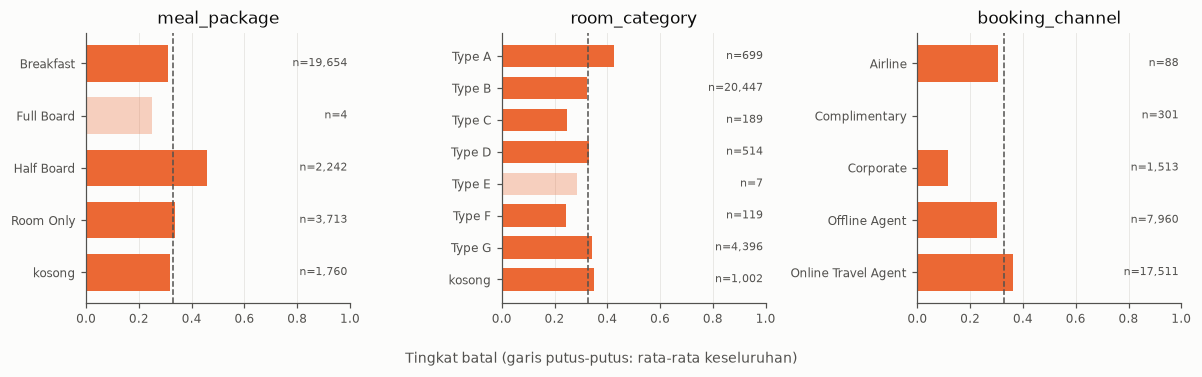

meal_package       chi2=    202.6  dof=4  p=1.04e-42
room_category      chi2=     49.7  dof=7  p=1.65e-08
booking_channel    chi2=    585.2  dof=4  p=2.52e-125

Kategori langka:
Full Board   train=  4  test=  1
Type E       train=  7  test=  0
Airline      train= 88  test= 33


In [14]:
plot_rate_grid(train, CFG.CAT_COLS, 3, 'categorical_rates', (11, 3.4))

for col in CFG.CAT_COLS:
    table = pd.crosstab(train[col].fillna('kosong'), train[CFG.TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    print(f'{col:18} chi2={chi2:9.1f}  dof={dof}  p={p:.2e}')

print('\nKategori langka:')
for col, value in [('meal_package', 'Full Board'), ('room_category', 'Type E'), ('booking_channel', 'Airline')]:
    print(f'{value:12} train={train[col].eq(value).sum():3}  test={test[col].eq(value).sum():3}')

#### Insights

> `booking_channel` paling kuat di antara ketiganya. Complimentary tidak pernah batal, Corporate 11,5%, dan Online Travel Agent 36,4%. Pada `meal_package`, Half Board menonjol dengan 45,9%, sedangkan `room_category` paling lemah.

> Kategori langka perlu digabung agar tidak menghasilkan kolom one-hot yang hampir selalu nol. Full Board dan Type E adalah kasus terparah. Baris kosong pada kedua kolom memiliki tingkat batal mendekati rata-rata, sehingga cukup diberi kategori sendiri.

---

# Pola Waktu <a name="6"></a>

---

Tanggal kedatangan tersedia sebagai tiga kolom terpisah. Bagian ini menyusunnya kembali untuk melihat apakah target berubah terhadap waktu, dan apakah pembagian train dan test bersifat acak atau temporal.

## Tren Bulanan

Volume dan tingkat batal ditampilkan pada dua panel terpisah menurut bulan kedatangan. Jumlah baris test ikut ditampilkan untuk memeriksa cara pembagian data.

Tanggal tidak valid: train=0, test=0
Rentang train: 2023-07-01 s.d. 2024-12-30
Rentang test : 2023-07-01 s.d. 2024-12-30


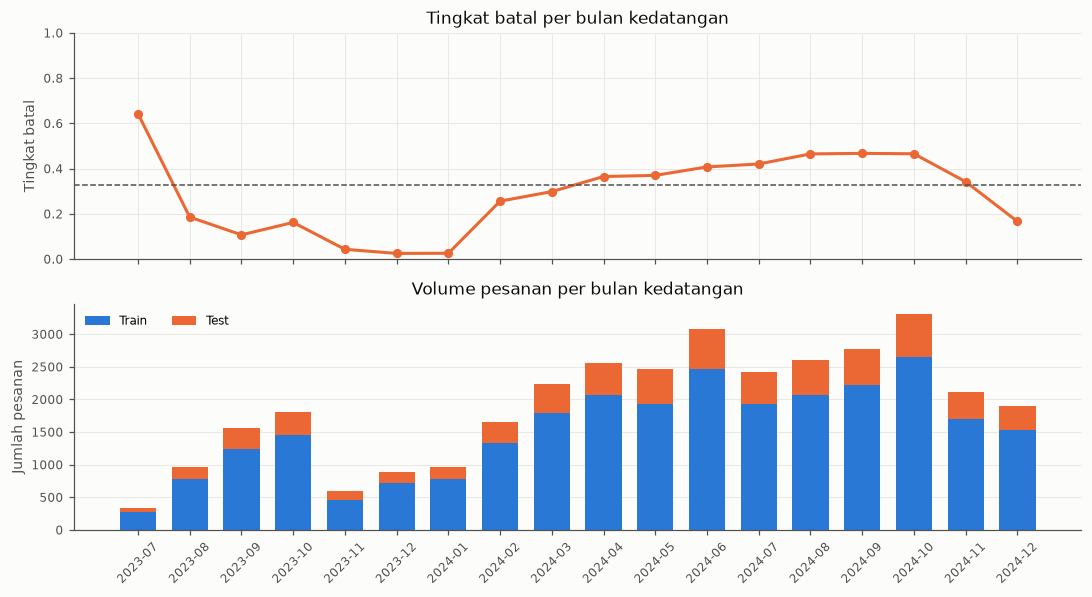

            size   mean  test_size  test_share
arrival_ym                                    
2023-07      274  0.642         66       0.194
2023-08      776  0.186        189       0.196
2023-09     1241  0.107        320       0.205
2023-10     1451  0.162        357       0.197
2023-11      463  0.043        137       0.228
2023-12      719  0.025        175       0.196
2024-01      777  0.026        186       0.193
2024-02     1336  0.256        321       0.194
2024-03     1786  0.298        453       0.202
2024-04     2066  0.365        485       0.190
2024-05     1935  0.370        533       0.216
2024-06     2462  0.407        610       0.199
2024-07     1924  0.420        489       0.203
2024-08     2067  0.465        541       0.207
2024-09     2217  0.467        549       0.198
2024-10     2651  0.465        651       0.197
2024-11     1696  0.342        411       0.195
2024-12     1532  0.166        371       0.195


In [15]:
def add_period(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out['arrival_ym'] = (
        out['arrival_year'].astype(str) + '-' + out['arrival_month'].astype(str).str.zfill(2)
    )
    out['arrival_date'] = pd.to_datetime(
        {'year': out['arrival_year'], 'month': out['arrival_month'], 'day': out['arrival_day']},
        errors='coerce',
    )
    return out

train_t, test_t = add_period(train), add_period(test)
print(f'Tanggal tidak valid: train={train_t.arrival_date.isna().sum()}, test={test_t.arrival_date.isna().sum()}')
print(f'Rentang train: {train_t.arrival_date.min().date()} s.d. {train_t.arrival_date.max().date()}')
print(f'Rentang test : {test_t.arrival_date.min().date()} s.d. {test_t.arrival_date.max().date()}')

monthly = train_t.groupby('arrival_ym')[CFG.TARGET].agg(['size', 'mean'])
monthly['test_size'] = test_t.groupby('arrival_ym').size()
monthly['test_share'] = monthly['test_size'] / (monthly['test_size'] + monthly['size'])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
ax1.plot(monthly.index, monthly['mean'], color=CFG.POS_COLOR, linewidth=2, marker='o', markersize=5)
ax1.axhline(train[CFG.TARGET].mean(), color=CFG.MUTED, linewidth=1, linestyle='--')
ax1.set_ylim(0, 1)
ax1.set_ylabel('Tingkat batal')
ax1.set_title('Tingkat batal per bulan kedatangan')

ax2.bar(monthly.index, monthly['size'], color=CFG.NEG_COLOR, width=0.7, label='Train')
ax2.bar(monthly.index, monthly['test_size'], bottom=monthly['size'], color=CFG.POS_COLOR,
        width=0.7, label='Test')
ax2.set_ylabel('Jumlah pesanan')
ax2.set_title('Volume pesanan per bulan kedatangan')
ax2.legend(ncols=2, loc='upper left')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis='x', visible=False)
save_fig('monthly_trend')

print(monthly.round(3).to_string())

#### Insights

> Train dan test mencakup rentang tanggal yang sama, dan porsi test per bulan stabil pada 19,0% sampai 22,8%. Pembagian data bersifat acak, bukan temporal. Stratified K-Fold karena itu mewakili kondisi test Kaggle.

> Tingkat batal bergerak dari 2,5% pada Desember 2023 hingga 64,2% pada Juli 2023, walaupun Juli 2023 hanya memuat 274 baris. Periode kedatangan membawa sinyal yang besar.

## Bulan Kalender dan Hari

Periode yang sama pada dua tahun dibandingkan untuk membedakan musim berulang dari perubahan antartahun. Hari dalam pekan dan tanggal diperiksa sebagai kandidat fitur.

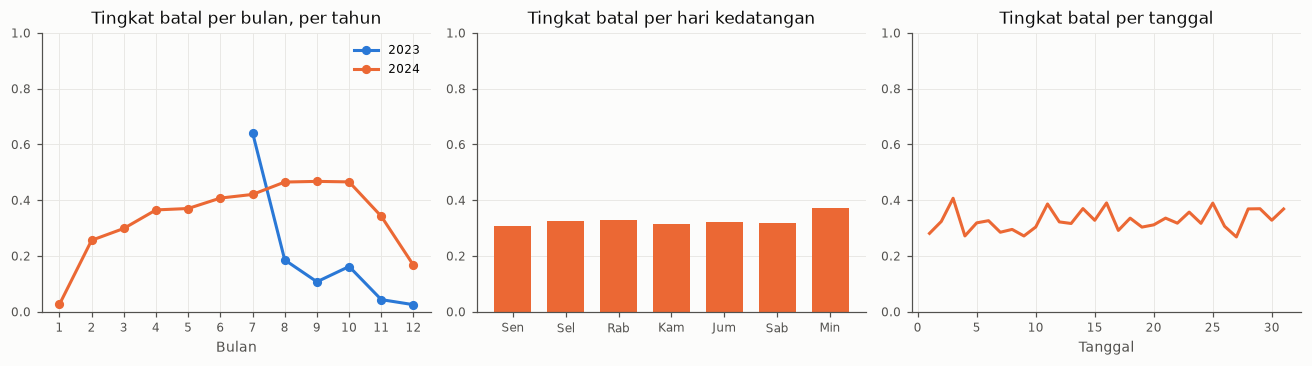

Rentang tingkat batal per hari  : 0.305 - 0.372
Rentang tingkat batal per tanggal: 0.268 - 0.407


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))

for year, color in [(2023, CFG.NEG_COLOR), (2024, CFG.POS_COLOR)]:
    rate = train[train['arrival_year'].eq(year)].groupby('arrival_month')[CFG.TARGET].mean()
    axes[0].plot(rate.index, rate.values, color=color, linewidth=2, marker='o', markersize=5, label=str(year))
axes[0].set_xticks(range(1, 13))
axes[0].set_ylim(0, 1)
axes[0].set_title('Tingkat batal per bulan, per tahun')
axes[0].set_xlabel('Bulan')
axes[0].legend()

dow = train_t.groupby(train_t['arrival_date'].dt.day_of_week)[CFG.TARGET].mean()
axes[1].bar(['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min'], dow.values, color=CFG.POS_COLOR, width=0.7)
axes[1].set_ylim(0, 1)
axes[1].set_title('Tingkat batal per hari kedatangan')
axes[1].grid(axis='x', visible=False)

day = train.groupby('arrival_day')[CFG.TARGET].mean()
axes[2].plot(day.index, day.values, color=CFG.POS_COLOR, linewidth=2)
axes[2].set_ylim(0, 1)
axes[2].set_title('Tingkat batal per tanggal')
axes[2].set_xlabel('Tanggal')
save_fig('calendar_patterns')

print('Rentang tingkat batal per hari  :', round(dow.min(), 3), '-', round(dow.max(), 3))
print('Rentang tingkat batal per tanggal:', round(day.min(), 3), '-', round(day.max(), 3))

#### Insights

> Pola ini bukan musiman murni. Oktober bernilai 16,2% pada 2023 dan 46,5% pada 2024, sedangkan Juli bernilai 64,2% dan 42,0%. `arrival_month` saja tidak cukup, sehingga kombinasi tahun dan bulan perlu diperlakukan sebagai kategori.

> Hari kedatangan (30,5% sampai 37,2%) dan tanggal (26,8% sampai 40,7%) jauh lebih lemah. Kombinasi tahun-bulan efektif untuk Kaggle karena test berada pada periode yang sama, tetapi tidak akan berlaku untuk bulan baru pada penerapan nyata.

## Interaksi Lead Time dan Periode

Bila efek lead time berbeda antarperiode, kedua fitur berinteraksi dan batas keputusan yang lurus tidak cukup. Sel dengan kurang dari 30 baris dikosongkan.

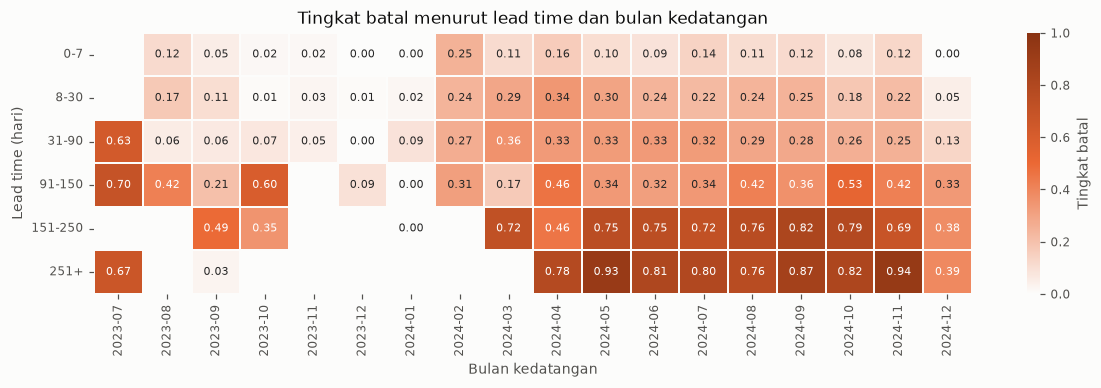

In [17]:
lead_group = pd.cut(
    train_t['days_before_arrival'], [-1, 7, 30, 90, 150, 250, 500],
    labels=['0-7', '8-30', '31-90', '91-150', '151-250', '251+'],
)
pivot_rate = train_t.pivot_table(
    index=lead_group, columns='arrival_ym', values=CFG.TARGET, aggfunc='mean', observed=True
)
pivot_size = train_t.pivot_table(
    index=lead_group, columns='arrival_ym', values=CFG.TARGET, aggfunc='size', observed=True
)

fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(
    pivot_rate.where(pivot_size >= 30), cmap=SEQUENTIAL, vmin=0, vmax=1, annot=True, fmt='.2f',
    annot_kws={'size': 7}, linewidths=1, linecolor=CFG.SURFACE,
    cbar_kws={'label': 'Tingkat batal'}, ax=ax,
)
ax.set_title('Tingkat batal menurut lead time dan bulan kedatangan')
ax.set_xlabel('Bulan kedatangan')
ax.set_ylabel('Lead time (hari)')
ax.tick_params(axis='y', rotation=0)
ax.grid(False)
save_fig('lead_period_interaction')

#### Insights

> Efek lead time bergantung pada periode. Lead time 151 sampai 250 hari memiliki tingkat batal 0,72 sampai 0,82 pada Mei hingga Oktober 2024, tetapi hanya 0,38 pada Desember 2024. Periode akhir 2023 hingga Januari 2024 rendah untuk lead time di bawah 90 hari. Interaksi ini mendukung penggunaan kernel nonlinear.

## Bulan Pemesanan

Tanggal pemesanan tidak tersedia langsung, tetapi dapat diturunkan dari tanggal kedatangan dikurangi `days_before_arrival`. Fitur ini diketahui saat pesanan dibuat, sehingga tidak membocorkan target.

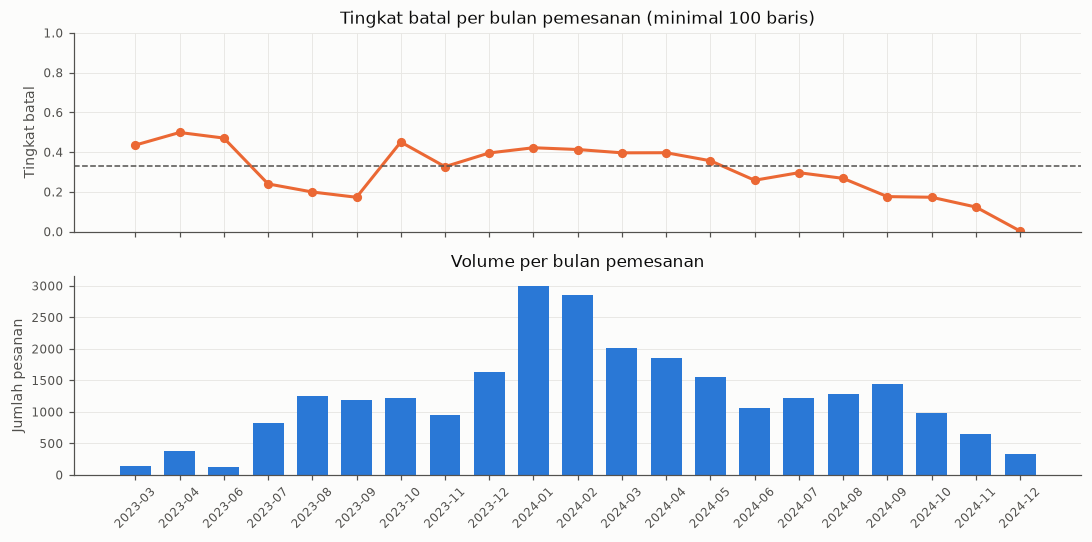

Jumlah bulan pemesanan unik: 26
            size   mean
booking_ym             
2023-03      147  0.435
2023-04      375  0.499
2023-06      119  0.471
2023-07      817  0.240
2023-08     1250  0.199
2023-09     1193  0.173
2023-10     1216  0.451
2023-11      949  0.327
2023-12     1625  0.396
2024-01     3003  0.422
2024-02     2852  0.413
2024-03     2006  0.396
2024-04     1862  0.397
2024-05     1546  0.356
2024-06     1057  0.258
2024-07     1228  0.296
2024-08     1277  0.268
2024-09     1437  0.176
2024-10      978  0.173
2024-11      647  0.124
2024-12      333  0.003


In [18]:
def add_booking_month(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    booking_date = out['arrival_date'] - pd.to_timedelta(out['days_before_arrival'], unit='D')
    out['booking_ym'] = booking_date.dt.strftime('%Y-%m')
    return out

train_t, test_t = add_booking_month(train_t), add_booking_month(test_t)

booked = train_t.groupby('booking_ym')[CFG.TARGET].agg(['size', 'mean'])
booked = booked[booked['size'] >= 100]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax1.plot(booked.index, booked['mean'], color=CFG.POS_COLOR, linewidth=2, marker='o', markersize=5)
ax1.axhline(train[CFG.TARGET].mean(), color=CFG.MUTED, linewidth=1, linestyle='--')
ax1.set_ylim(0, 1)
ax1.set_ylabel('Tingkat batal')
ax1.set_title('Tingkat batal per bulan pemesanan (minimal 100 baris)')

ax2.bar(booked.index, booked['size'], color=CFG.NEG_COLOR, width=0.7)
ax2.set_ylabel('Jumlah pesanan')
ax2.set_title('Volume per bulan pemesanan')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis='x', visible=False)
save_fig('booking_month')

print(f'Jumlah bulan pemesanan unik: {train_t.booking_ym.nunique()}')
print(booked.round(3).to_string())

#### Insights

> Bulan pemesanan membawa sinyal yang tidak identik dengan bulan kedatangan, misalnya lompatan dari 17,3% pada September 2023 ke 45,1% pada Oktober 2023.

> Penurunan hingga 0,3% pada Desember 2024 perlu dibaca hati-hati. Seluruh kedatangan berakhir pada Desember 2024, sehingga pesanan pada bulan itu pasti memiliki lead time pendek, dan lead time pendek memang jarang batal.

---

# Relevansi dan Redundansi Fitur <a name="7"></a>

---

Dua pertanyaan dijawab di sini, yaitu fitur mana yang membawa sinyal dan fitur mana yang saling tumpang tindih. Korelasi hanya menangkap hubungan monotonik, sehingga mutual information ikut digunakan untuk hubungan nonlinear.

## Korelasi Spearman

Spearman dipilih karena banyak fitur miring dan berupa hitungan. Target disertakan sebagai baris terakhir.

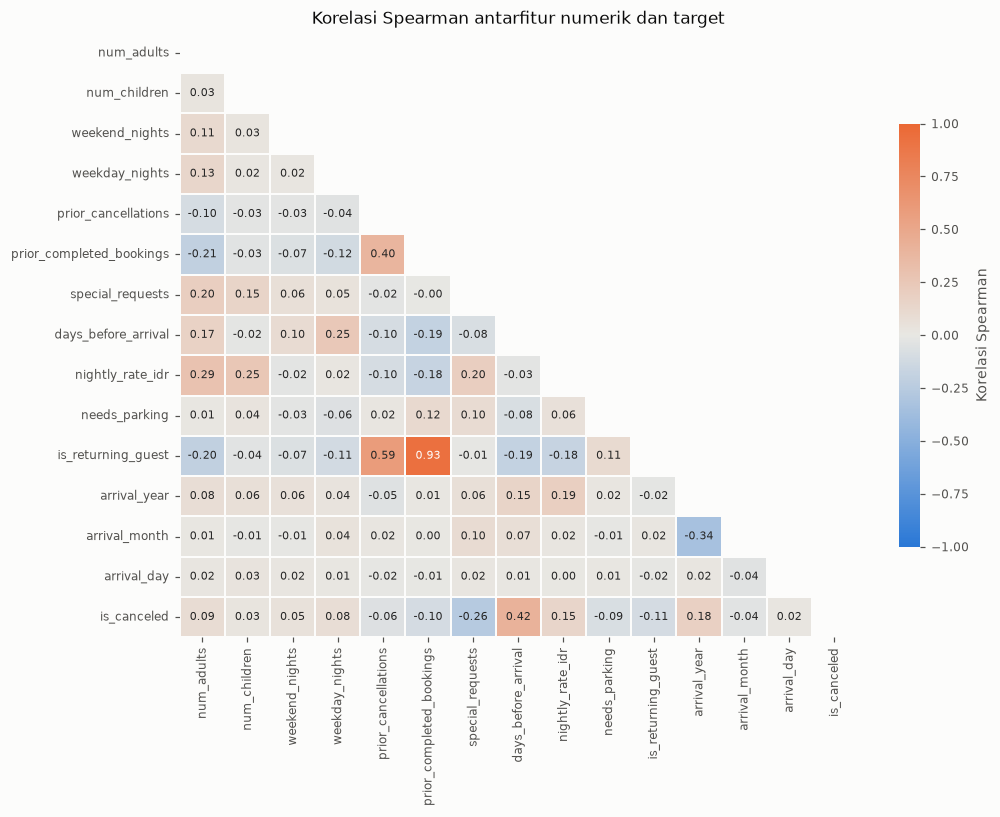

Pasangan fitur dengan |rho| terbesar:
prior_completed_bookings  is_returning_guest          0.932
prior_cancellations       is_returning_guest          0.587
                          prior_completed_bookings    0.396
arrival_year              arrival_month              -0.341
num_adults                nightly_rate_idr            0.290
num_children              nightly_rate_idr            0.254

Korelasi terhadap target:
days_before_arrival         0.418
special_requests           -0.261
arrival_year                0.180
nightly_rate_idr            0.148
is_returning_guest         -0.107
prior_completed_bookings   -0.102
num_adults                  0.092
needs_parking              -0.086
weekday_nights              0.083
prior_cancellations        -0.057
weekend_nights              0.053
arrival_month              -0.037
num_children                0.025
arrival_day                 0.020


In [19]:
corr = train[CFG.NUM_COLS + [CFG.TARGET]].corr(method='spearman')

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(
    corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap=DIVERGING, vmin=-1, vmax=1,
    annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=1, linecolor=CFG.SURFACE,
    cbar_kws={'label': 'Korelasi Spearman', 'shrink': 0.7}, ax=ax,
)
ax.set_title('Korelasi Spearman antarfitur numerik dan target')
ax.grid(False)
save_fig('spearman_correlation')

pairs = corr.drop(index=CFG.TARGET, columns=CFG.TARGET).where(
    np.triu(np.ones((len(CFG.NUM_COLS), len(CFG.NUM_COLS)), dtype=bool), k=1)
).stack()
print('Pasangan fitur dengan |rho| terbesar:')
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(6).round(3).to_string())

target_corr = corr[CFG.TARGET].drop(CFG.TARGET)
print('\nKorelasi terhadap target:')
print(target_corr.reindex(target_corr.abs().sort_values(ascending=False).index).round(3).to_string())

#### Insights

> Korelasi terhadap target terkuat dimiliki `days_before_arrival` (0,418) dan `special_requests` (-0,261). Redundansi utama adalah `prior_completed_bookings` dengan `is_returning_guest` (0,932). Selain kelompok riwayat tamu, tidak ada pasangan fitur dengan korelasi tinggi.

## Mutual Information dan Cramer's V

Mutual information dihitung pada train saja, setelah imputasi sementara dengan median atau label kosong. Imputasi ini hanya untuk pemeringkatan dan tidak dipakai pada model. Fitur turunan disertakan untuk menilai manfaatnya.

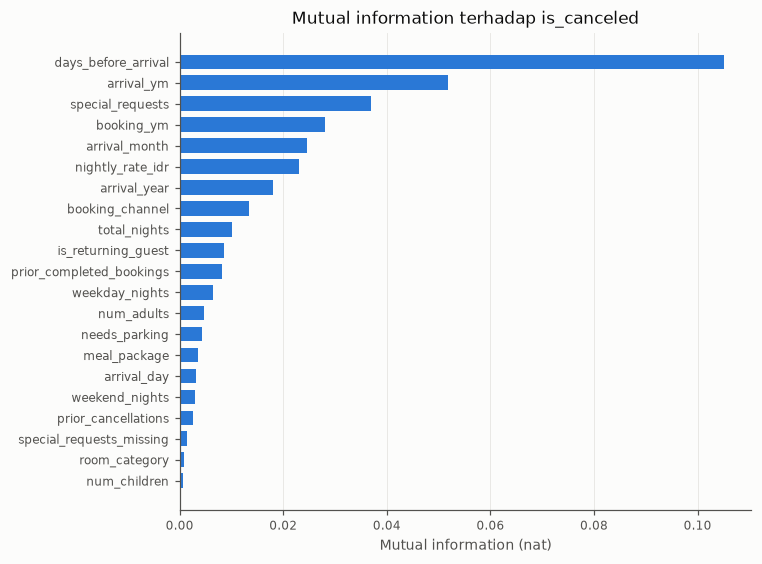

days_before_arrival         0.1051
arrival_ym                  0.0517
special_requests            0.0369
booking_ym                  0.0280
arrival_month               0.0245
nightly_rate_idr            0.0231
arrival_year                0.0181
booking_channel             0.0135
total_nights                0.0102
is_returning_guest          0.0085
prior_completed_bookings    0.0082
weekday_nights              0.0064
num_adults                  0.0046
needs_parking               0.0042
meal_package                0.0035
arrival_day                 0.0032
weekend_nights              0.0029
prior_cancellations         0.0026
special_requests_missing    0.0014
room_category               0.0009
num_children                0.0007

Cramer V terhadap target:
meal_package       0.086
room_category      0.043
booking_channel    0.146
arrival_ym         0.298
booking_ym         0.225


In [20]:
def cramers_v(a: pd.Series, b: pd.Series) -> float:
    table = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))))

mi_frame = train_t[CFG.FEATURES + ['arrival_ym', 'booking_ym']].copy()
mi_frame['total_nights'] = mi_frame['weekend_nights'] + mi_frame['weekday_nights']
mi_frame['special_requests_missing'] = mi_frame['special_requests'].isna().astype(int)

cat_like = CFG.CAT_COLS + ['arrival_ym', 'booking_ym']
num_like = [c for c in mi_frame.columns if c not in cat_like]
mi_frame[num_like] = mi_frame[num_like].fillna(mi_frame[num_like].median())
mi_frame[cat_like] = OrdinalEncoder().fit_transform(mi_frame[cat_like].fillna('kosong').astype(str))

discrete = [c != 'days_before_arrival' and c != 'nightly_rate_idr' for c in mi_frame.columns]
mi = pd.Series(
    mutual_info_classif(mi_frame, train[CFG.TARGET], discrete_features=discrete, random_state=CFG.SEED),
    index=mi_frame.columns,
).sort_values()

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.barh(mi.index, mi.values, color=CFG.NEG_COLOR, height=0.7)
ax.set_title('Mutual information terhadap is_canceled')
ax.set_xlabel('Mutual information (nat)')
ax.grid(axis='y', visible=False)
save_fig('mutual_information')

print(mi.sort_values(ascending=False).round(4).to_string())
print('\nCramer V terhadap target:')
for col in cat_like:
    print(f'{col:18} {cramers_v(train_t[col].fillna("kosong"), train[CFG.TARGET]):.3f}')

#### Insights

> Mutual information menempatkan `days_before_arrival` di puncak (0,105), diikuti `arrival_ym` (0,052), `special_requests` (0,037), dan `booking_ym` (0,028). `arrival_ym` jauh melampaui `arrival_month` (0,025) dan memiliki Cramer's V tertinggi (0,298), sehingga mendukung kombinasi tahun dan bulan.

> `room_category` dan `num_children` memiliki nilai terendah. Ukuran ini univariat dan tidak melihat interaksi, sehingga fitur lemah tidak langsung dibuang. Pemilihan fitur diputuskan melalui validasi silang.

---

# Perbandingan Train dan Test <a name="8"></a>

---

Skor validasi hanya mewakili skor test bila kedua berkas berasal dari distribusi yang sama. Population Stability Index (PSI) dihitung dengan bin dari train, lalu test dievaluasi pada bin tersebut, sehingga kedua berkas tetap terpisah. Nilai di bawah 0,1 umumnya dianggap stabil.

In [21]:
def psi(expected: pd.Series, actual: pd.Series, bins: int = 10, eps: float = 1e-4) -> float:
    if expected.nunique() > 20:
        edges = np.unique(expected.dropna().quantile(np.linspace(0, 1, bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
        expected, actual = pd.cut(expected, edges), pd.cut(actual, edges)
    e = expected.astype(object).where(expected.notna(), 'kosong').value_counts(normalize=True)
    a = actual.astype(object).where(actual.notna(), 'kosong').value_counts(normalize=True)
    e, a = e.align(a, fill_value=0)
    e, a = e.clip(lower=eps), a.clip(lower=eps)
    return float(((a - e) * np.log(a / e)).sum())

drift = pd.DataFrame({
    'psi': {c: psi(train[c], test[c]) for c in CFG.FEATURES},
    'ks': {c: stats.ks_2samp(train[c].dropna(), test[c].dropna()).statistic for c in CFG.NUM_COLS},
}).sort_values('psi', ascending=False)
display(drift.round(4))

for col in CFG.CAT_COLS:
    unseen = set(test[col].dropna()) - set(train[col].dropna())
    print(f'{col:18} kategori baru pada test: {unseen or "tidak ada"}')

share = monthly['test_share']
print(f'Porsi test per bulan: min={share.min():.3f}, max={share.max():.3f}')

,psi,ks
arrival_day,0.0021,0.0149
nightly_rate_idr,0.0020,0.0070
weekday_nights,0.0016,0.0044
weekend_nights,0.0014,0.0090
arrival_month,0.0014,0.0068
num_adults,0.0013,0.0034
prior_cancellations,0.0012,0.0029
days_before_arrival,0.0011,0.0059
special_requests,0.0010,0.0066
booking_channel,0.0008,NaN


meal_package       kategori baru pada test: tidak ada
room_category      kategori baru pada test: tidak ada
booking_channel    kategori baru pada test: tidak ada
Porsi test per bulan: min=0.190, max=0.228


#### Insights

> Tidak ada pergeseran distribusi. PSI tertinggi 0,0021 dan KS tertinggi 0,0149, jauh di bawah batas 0,1, dan tidak ada kategori baru pada test. Skor validasi silang dapat dijadikan perkiraan skor test.

---

# Implikasi untuk SVM <a name="9"></a>

---

Bagian ini menguji langsung pertanyaan perancangan SVM memakai `sklearn.svm.SVC` sebagai alat ukur cepat. Hasilnya bersifat arahan, bukan hasil akhir, karena hyperparameter belum dituning. Seluruh preprocessing berada di dalam pipeline dan duplikat dibuang lebih dulu.

## Skala Fitur

Kernel Gaussian dan polynomial bergantung pada jarak atau hasil kali titik, sehingga fitur berskala besar dapat mendominasi. Kemiringan juga diperiksa untuk menilai perlunya transformasi.

In [22]:
scale = pd.DataFrame({
    'std': train[CFG.NUM_COLS].std(),
    'range': train[CFG.NUM_COLS].max() - train[CFG.NUM_COLS].min(),
    'skew': train[CFG.NUM_COLS].skew(),
}).sort_values('range', ascending=False)
scale['range_vs_median_range'] = scale['range'] / scale['range'].median()
scale.round(2)

,std,range,skew,range_vs_median_range
nightly_rate_idr,587936.77,9165000.0,0.67,872857.14
days_before_arrival,85.97,448.0,1.30,42.67
prior_completed_bookings,1.69,58.0,20.08,5.52
arrival_day,8.77,30.0,0.03,2.86
weekday_nights,1.42,17.0,1.65,1.62
prior_cancellations,0.36,13.0,25.95,1.24
arrival_month,3.07,11.0,-0.34,1.05
num_children,0.43,10.0,4.66,0.95
weekend_nights,0.88,7.0,0.75,0.67
special_requests,0.80,5.0,1.05,0.48


#### Insights

> Rentang `nightly_rate_idr` sekitar 870 ribu kali median rentang fitur lain, sehingga tanpa scaling jarak antarbaris praktis hanya ditentukan tarif. `prior_cancellations` (skew 25,95) dan `prior_completed_bookings` (skew 20,08) sangat miring, sehingga log atau pemangkasan perlu diterapkan sebelum standardisasi.

## Pipeline Uji

Dua set fitur dibandingkan. Set `raw` memakai kolom apa adanya. Set `engineered` menerapkan temuan EDA, yaitu bulan kedatangan dan bulan pemesanan sebagai kategori, total malam, log lead time, penanda tarif nol, dan penanda `special_requests` kosong.

In [23]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out['total_nights'] = out['weekend_nights'] + out['weekday_nights']
    out['lead_log'] = np.log1p(out['days_before_arrival'])
    out['rate_is_zero'] = out['nightly_rate_idr'].eq(0).astype(float)
    out['special_requests_missing'] = out['special_requests'].isna().astype(float)
    arrival = pd.to_datetime(
        {'year': out['arrival_year'], 'month': out['arrival_month'], 'day': out['arrival_day']}
    )
    booking = arrival - pd.to_timedelta(out['days_before_arrival'], unit='D')
    out['arrival_ym'] = arrival.dt.strftime('%Y-%m')
    out['booking_ym'] = booking.dt.strftime('%Y-%m')
    return out

FEATURE_SETS = {
    'raw': {'num': CFG.NUM_COLS, 'cat': CFG.CAT_COLS},
    'engineered': {
        'num': CFG.COUNT_COLS + CFG.CONT_COLS + CFG.BIN_COLS + [
            'total_nights', 'lead_log', 'rate_is_zero', 'special_requests_missing',
        ],
        'cat': CFG.CAT_COLS + ['arrival_ym', 'booking_ym'],
    },
}

def make_preprocessor(feature_set: str, scale: bool = True) -> Pipeline:
    spec = FEATURE_SETS[feature_set]
    num_steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scale', StandardScaler()))
    cat_steps = [
        ('impute', SimpleImputer(strategy='constant', fill_value='kosong')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]
    columns = ColumnTransformer([
        ('num', Pipeline(num_steps), spec['num']),
        ('cat', Pipeline(cat_steps), spec['cat']),
    ])
    return Pipeline([('features', FunctionTransformer(add_features)), ('columns', columns)])

def make_model(feature_set: str, estimator, scale: bool = True) -> Pipeline:
    return Pipeline([('prep', make_preprocessor(feature_set, scale)), ('clf', estimator)])

clean = train.drop_duplicates(subset=CFG.FEATURES + [CFG.TARGET]).reset_index(drop=True)
X_all, y_all = clean[CFG.FEATURES], clean[CFG.TARGET]

for name in FEATURE_SETS:
    width = make_preprocessor(name).fit_transform(X_all).shape[1]
    print(f'Dimensi set {name}: {width}')
print(f'Baris setelah buang duplikat: {len(clean)}')

Dimensi set raw: 32


Dimensi set engineered: 78
Baris setelah buang duplikat: 27309


## Reduksi Dimensi

PCA dipasang pada set `engineered` untuk melihat jumlah komponen yang menyimpan variansi serta keterpisahan kelas pada dua komponen pertama. Proyeksi ini juga menjadi kandidat visualisasi bidang pemisah pada bonus SVM.

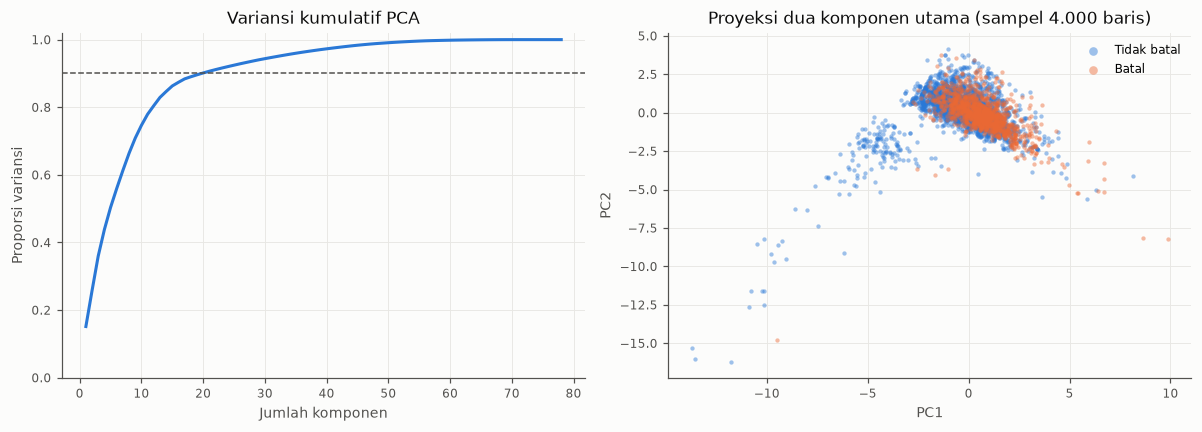

Komponen untuk 80% variansi: 12 dari 78
Komponen untuk 90% variansi: 20 dari 78
Komponen untuk 95% variansi: 32 dari 78
Komponen untuk 99% variansi: 50 dari 78
Variansi dua komponen pertama: 0.257
ROC-AUC model linear pada 2 komponen (pembanding kasar): 0.693


In [24]:
Z = make_preprocessor('engineered').fit_transform(X_all)
pca = PCA(random_state=CFG.SEED).fit(Z)
cumulative = np.cumsum(pca.explained_variance_ratio_)
coords = pca.transform(Z)[:, :2]

rng = np.random.default_rng(CFG.SEED)
idx = rng.choice(len(Z), 4000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(1, len(cumulative) + 1), cumulative, color=CFG.NEG_COLOR, linewidth=2)
axes[0].axhline(0.9, color=CFG.MUTED, linewidth=1, linestyle='--')
axes[0].set_ylim(0, 1.02)
axes[0].set_title('Variansi kumulatif PCA')
axes[0].set_xlabel('Jumlah komponen')
axes[0].set_ylabel('Proporsi variansi')

for value, color, label in [(0, CFG.NEG_COLOR, 'Tidak batal'), (1, CFG.POS_COLOR, 'Batal')]:
    mask = y_all.values[idx] == value
    axes[1].scatter(*coords[idx][mask].T, s=8, alpha=0.45, color=color, label=label, linewidths=0)
axes[1].set_title('Proyeksi dua komponen utama (sampel 4.000 baris)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(markerscale=2)
save_fig('pca_projection')

for target in (0.8, 0.9, 0.95, 0.99):
    print(f'Komponen untuk {target:.0%} variansi: {int(np.searchsorted(cumulative, target) + 1)} dari {Z.shape[1]}')
print(f'Variansi dua komponen pertama: {cumulative[1]:.3f}')

auc_2d = cross_validate(
    LogisticRegression(max_iter=1000), coords, y_all, scoring='roc_auc',
    cv=StratifiedKFold(CFG.PROBE_FOLDS, shuffle=True, random_state=CFG.SEED),
)['test_score'].mean()
print(f'ROC-AUC model linear pada 2 komponen (pembanding kasar): {auc_2d:.3f}')

#### Insights

> Dua komponen utama hanya menyimpan 25,7% variansi, dan model linear pada proyeksi ini mencapai ROC-AUC 0,693, jauh di bawah model pada fitur penuh. Kedua kelas juga banyak bertumpuk. Proyeksi 2D sebaiknya dipakai hanya untuk gambar bonus, dan gambar itu tidak mewakili performa model.

> Dibutuhkan 20 dari 78 komponen untuk 90% variansi. PCA tidak mendesak bagi SVM di sini, karena 78 dimensi tergolong kecil dan biaya utama SVM berasal dari jumlah baris.

## Efek Kelompok dan Skema Validasi

Pesanan dengan tanggal kedatangan dan lead time identik kemungkinan berasal dari rombongan yang sama. Bila rombongan batal bersama, fold acak dapat memecah satu rombongan ke latih dan validasi. Keseragaman label dibandingkan terhadap dua pembanding, yaitu tingkat batal global dan probabilitas per baris dari model tanpa informasi kelompok. Skor fold acak lalu dibandingkan dengan fold yang menjaga satu kelompok tetap utuh.

In [25]:
def booking_key(df: pd.DataFrame) -> pd.Series:
    arrival = pd.to_datetime(
        {'year': df['arrival_year'], 'month': df['arrival_month'], 'day': df['arrival_day']}
    )
    lead = df['days_before_arrival']
    return (arrival.dt.strftime('%Y%m%d') + '|' + lead.astype('Int64').astype(str)).where(lead.notna())

def evaluate_splits(splits):
    rows, oof = [], np.zeros(len(X_all))
    for fit_idx, val_idx in splits:
        X_fit, y_fit = X_all.iloc[fit_idx], y_all.iloc[fit_idx]
        X_val, y_val = X_all.iloc[val_idx], y_all.iloc[val_idx]
        booster = make_model('engineered', HistGradientBoostingClassifier(random_state=CFG.SEED))
        svm = make_model('engineered', SVC(kernel='rbf'))
        oof[val_idx] = booster.fit(X_fit, y_fit).predict_proba(X_val)[:, 1]
        scores = svm.fit(X_fit, y_fit).decision_function(X_val)
        rows.append({
            'boosting_auc': roc_auc_score(y_val, oof[val_idx]),
            'svm_auc': roc_auc_score(y_val, scores),
            'svm_macro_f1': f1_score(y_val, scores > 0, average='macro'),
        })
    return pd.DataFrame(rows).mean(), oof

keys = booking_key(X_all)
group_ids = keys.fillna(pd.Series(X_all.index.astype(str), index=X_all.index))

random_splits = StratifiedKFold(CFG.PROBE_FOLDS, shuffle=True, random_state=CFG.SEED).split(X_all, y_all)
group_splits = GroupKFold(CFG.PROBE_FOLDS).split(X_all, y_all, group_ids)
random_score, _ = evaluate_splits(random_splits)
group_score, group_oof = evaluate_splits(group_splits)
display(pd.DataFrame({'fold_acak': random_score, 'fold_kelompok': group_score}).round(4))

frame = pd.DataFrame({'key': keys, 'y': y_all, 'p': np.clip(group_oof, 1e-6, 1 - 1e-6)}).dropna(subset=['key'])
frame['log_p'], frame['log_q'] = np.log(frame['p']), np.log1p(-frame['p'])
groups = frame.groupby('key').agg(
    size=('y', 'size'), rate=('y', 'mean'), log_p=('log_p', 'sum'), log_q=('log_q', 'sum')
)
base = y_all.mean()
groups['pure'] = groups['rate'].isin([0, 1])
groups['expected_global'] = base ** groups['size'] + (1 - base) ** groups['size']
groups['expected_model'] = np.exp(groups['log_p']) + np.exp(groups['log_q'])
groups['bin'] = pd.cut(groups['size'], [1, 4, 9, 1000], labels=['2-4', '5-9', '10+'])

purity = groups.dropna(subset=['bin']).groupby('bin', observed=True).agg(
    n_grup=('size', 'size'), n_baris=('size', 'sum'), seragam=('pure', 'mean'),
    harapan_global=('expected_global', 'mean'), harapan_model=('expected_model', 'mean'),
)
display(purity.round(3))

seen_keys = set(keys.dropna())
print(f'Baris test dengan kunci kelompok yang ada di train: {booking_key(test).isin(seen_keys).mean():.3f}')

,fold_acak,fold_kelompok
boosting_auc,0.9304,0.9296
svm_auc,0.8943,0.8947
svm_macro_f1,0.8158,0.8148


,n_grup,n_baris,seragam,harapan_global,harapan_model
bin,,,,,
2-4,4354,10393,0.722,0.483,0.667
5-9,388,2317,0.678,0.105,0.530
10+,36,436,0.611,0.011,0.451


Baris test dengan kunci kelompok yang ada di train: 0.486


#### Insights

> Skema validasi tidak mengubah kesimpulan. Macro F1 SVM adalah 0,8158 pada fold acak dan 0,8148 pada fold kelompok, dan ROC-AUC boosting 0,9304 terhadap 0,9296. Stratified K-Fold dapat digunakan.

> Efek rombongan nyata tetapi moderat. Pada grup minimal 10 baris, 61,1% berlabel seragam, dibandingkan harapan 45,1% dari model tanpa informasi kelompok. Pembanding tingkat batal global (1,1%) menyesatkan, karena sebagian besar keseragaman sudah dijelaskan oleh lead time dan periode.

## Uji Kernel dan Scaling

Kernel, set fitur, scaling, dan bobot kelas dibandingkan dengan hyperparameter bawaan pada sampel berstrata. Logistic Regression dan gradient boosting hanya menjadi pembanding untuk memperkirakan batas atas sinyal, dan tidak akan digunakan untuk submission.

In [26]:
X_probe, _, y_probe, _ = train_test_split(
    X_all, y_all, train_size=CFG.PROBE_SAMPLE, stratify=y_all, random_state=CFG.SEED
)
cv = StratifiedKFold(CFG.PROBE_FOLDS, shuffle=True, random_state=CFG.SEED)
scoring = ['f1_macro', 'roc_auc', 'accuracy']

experiments = {
    'SVM linear, raw': make_model('raw', SVC(kernel='linear')),
    'SVM poly d=3, raw': make_model('raw', SVC(kernel='poly', degree=3, coef0=1)),
    'SVM gaussian, raw': make_model('raw', SVC(kernel='rbf')),
    'SVM linear, engineered': make_model('engineered', SVC(kernel='linear')),
    'SVM poly d=3, engineered': make_model('engineered', SVC(kernel='poly', degree=3, coef0=1)),
    'SVM gaussian, engineered': make_model('engineered', SVC(kernel='rbf')),
    'SVM gaussian, engineered, balanced': make_model('engineered', SVC(kernel='rbf', class_weight='balanced')),
    'SVM gaussian, engineered, tanpa scaling': make_model('engineered', SVC(kernel='rbf'), scale=False),
    'Pembanding: logistic, engineered': make_model('engineered', LogisticRegression(max_iter=2000)),
    'Pembanding: gradient boosting, raw': make_model(
        'raw', HistGradientBoostingClassifier(random_state=CFG.SEED)
    ),
}

rows = []
for name, model in experiments.items():
    start = time.perf_counter()
    result = cross_validate(model, X_probe, y_probe, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        'eksperimen': name,
        'macro_f1': result['test_f1_macro'].mean(),
        'macro_f1_std': result['test_f1_macro'].std(),
        'roc_auc': result['test_roc_auc'].mean(),
        'accuracy': result['test_accuracy'].mean(),
        'detik': time.perf_counter() - start,
    })

probe = pd.DataFrame(rows).set_index('eksperimen')
probe.round(4)

,macro_f1,macro_f1_std,roc_auc,accuracy,detik
eksperimen,,,,,
"SVM linear, raw",0.7560,0.0030,0.8526,0.7967,3.2960
"SVM poly d=3, raw",0.7805,0.0070,0.8667,0.8160,1.9249
"SVM gaussian, raw",0.7768,0.0069,0.8645,0.8145,1.8104
"SVM linear, engineered",0.7672,0.0046,0.8637,0.8027,2.1272
"SVM poly d=3, engineered",0.7889,0.0030,0.8775,0.8213,1.9414
"SVM gaussian, engineered",0.7861,0.0075,0.8734,0.8208,1.2560
"SVM gaussian, engineered, balanced",0.7905,0.0033,0.8786,0.8078,1.9359
"SVM gaussian, engineered, tanpa scaling",0.4021,0.0000,0.5548,0.6725,2.0622
"Pembanding: logistic, engineered",0.7648,0.0090,0.8666,0.8010,0.1847


#### Insights

> Scaling bersifat wajib. Tanpa scaling, kernel Gaussian jatuh ke Macro F1 0,4021, sama dengan memprediksi seluruh baris tidak batal.

> Set `engineered` mengungguli `raw` pada ketiga kernel, dengan kenaikan Macro F1 sekitar 0,01. Kernel nonlinear mengungguli linear sekitar 0,02 (0,7889 dan 0,7861 terhadap 0,7672). Selisih polynomial dan Gaussian berada dalam simpangan baku pada hyperparameter bawaan, sehingga pemenangnya belum dapat ditentukan sebelum tuning.

> `class_weight='balanced'` menaikkan Macro F1 dari 0,7861 ke 0,7905, tetapi selisih ini masih dalam simpangan baku. Seluruh angka di sini berasal dari sampel 6.000 baris, sehingga hanya sahih untuk perbandingan antarkonfigurasi.

## Ukuran Data Latih

Biaya SVM kernel tumbuh jauh lebih cepat dari jumlah data, dan matriks kernel penuh tidak muat di memori untuk seluruh train. Kurva berikut mengukur skor, waktu latih, dan jumlah support vector terhadap ukuran sampel pada holdout tetap. Hasilnya menentukan kebutuhan solver pada implementasi from scratch.

,macro_f1,roc_auc,accuracy,n_support,fit_detik,predict_detik,kernel_matrix_gb
n_train,,,,,,,
1000,0.7507,0.8432,0.7940,564,0.0402,0.2462,0.0080
2000,0.7467,0.8490,0.7911,1067,0.0875,0.6448,0.0320
4000,0.7752,0.8677,0.8129,1998,0.4052,0.7806,0.1280
8000,0.7971,0.8800,0.8288,3752,0.9994,1.3056,0.5120
16000,0.8133,0.8942,0.8411,7024,4.8039,2.6040,2.0480
21847,0.8154,0.8979,0.8425,9430,8.0968,3.1265,3.8183


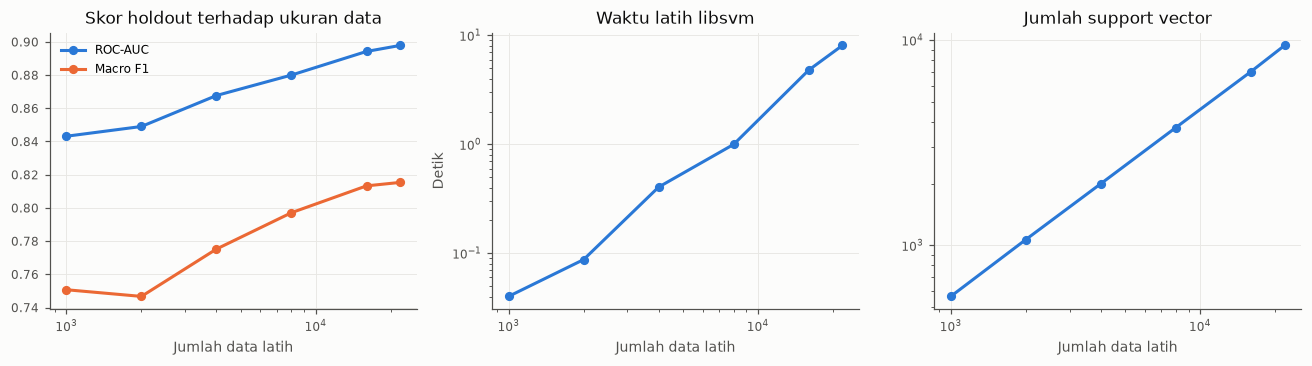

Eksponen pertumbuhan waktu latih: n^1.76


Pembanding boosting pada data yang sama: ROC-AUC=0.9309, Macro F1=0.8401
Matriks kernel penuh n=27309: 5.97 GB (float64), 2.98 GB (float32)


In [27]:
X_dev, X_hold, y_dev, y_hold = train_test_split(
    X_all, y_all, test_size=CFG.HOLDOUT_SIZE, stratify=y_all, random_state=CFG.SEED
)

rows = []
for size in CFG.SAMPLE_SIZES + [len(X_dev)]:
    if size < len(X_dev):
        X_sub, _, y_sub, _ = train_test_split(
            X_dev, y_dev, train_size=size, stratify=y_dev, random_state=CFG.SEED
        )
    else:
        X_sub, y_sub = X_dev, y_dev

    model = make_model('engineered', SVC(kernel='rbf'))
    start = time.perf_counter()
    model.fit(X_sub, y_sub)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    scores = model.decision_function(X_hold)
    predict_time = time.perf_counter() - start
    predictions = (scores > 0).astype(int)

    rows.append({
        'n_train': size,
        'macro_f1': f1_score(y_hold, predictions, average='macro'),
        'roc_auc': roc_auc_score(y_hold, scores),
        'accuracy': accuracy_score(y_hold, predictions),
        'n_support': int(model.named_steps['clf'].n_support_.sum()),
        'fit_detik': fit_time,
        'predict_detik': predict_time,
        'kernel_matrix_gb': size ** 2 * 8 / 1e9,
    })

curve = pd.DataFrame(rows).set_index('n_train')
display(curve.round(4))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for metric, color, label in [('roc_auc', CFG.NEG_COLOR, 'ROC-AUC'), ('macro_f1', CFG.POS_COLOR, 'Macro F1')]:
    axes[0].plot(curve.index, curve[metric], color=color, linewidth=2, marker='o', markersize=5, label=label)
axes[0].set_xscale('log')
axes[0].set_title('Skor holdout terhadap ukuran data')
axes[0].set_xlabel('Jumlah data latih')
axes[0].legend()

axes[1].plot(curve.index, curve['fit_detik'], color=CFG.NEG_COLOR, linewidth=2, marker='o', markersize=5)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Waktu latih libsvm')
axes[1].set_xlabel('Jumlah data latih')
axes[1].set_ylabel('Detik')

axes[2].plot(curve.index, curve['n_support'], color=CFG.NEG_COLOR, linewidth=2, marker='o', markersize=5)
axes[2].set_xscale('log')
axes[2].set_yscale('log')
axes[2].set_title('Jumlah support vector')
axes[2].set_xlabel('Jumlah data latih')
save_fig('svm_sample_size')

growth = np.polyfit(np.log(curve.index), np.log(curve['fit_detik']), 1)[0]
print(f'Eksponen pertumbuhan waktu latih: n^{growth:.2f}')

reference = make_model('engineered', HistGradientBoostingClassifier(random_state=CFG.SEED))
reference_score = reference.fit(X_dev, y_dev).predict_proba(X_hold)[:, 1]
print(f'Pembanding boosting pada data yang sama: ROC-AUC={roc_auc_score(y_hold, reference_score):.4f}, '
      f'Macro F1={f1_score(y_hold, reference_score > 0.5, average="macro"):.4f}')

n_full = len(X_all)
print(f'Matriks kernel penuh n={n_full}: {n_full ** 2 * 8 / 1e9:.2f} GB (float64), '
      f'{n_full ** 2 * 4 / 1e9:.2f} GB (float32)')

#### Insights

> Data tambahan terus membantu. Macro F1 naik dari 0,7507 pada 1.000 baris ke 0,8154 pada 21.847 baris. Sampel 4.000 baris kehilangan 0,040 Macro F1, sehingga subsampel kecil bukan pilihan yang baik. Kenaikan mulai melambat setelah 16.000 baris.

> Waktu latih tumbuh sekitar n^1,8 sampai n^1,9 (bervariasi antarrun) dan support vector mencakup sekitar 43% data. Matriks kernel penuh seluruh train membutuhkan 5,97 GB pada float64. Implementasi from scratch karena itu memerlukan SMO yang menghitung baris kernel sesuai kebutuhan dengan cache, bukan matriks penuh.

> Pada data yang sama, boosting mencapai Macro F1 0,8401, atau selisih sekitar 0,025 dari SVM tanpa tuning. Angka ini hanya pembanding batas sinyal, bukan target yang pasti tercapai, dan berasal dari satu holdout.

## Threshold untuk Macro F1

Batas keputusan bawaan SVM berada pada skor 0 dan tidak dioptimalkan untuk Macro F1. Pergeseran threshold dibandingkan dengan pembobotan kelas memakai prediksi out-of-fold pada data pengembangan, sehingga holdout tidak dipakai untuk memilih threshold.

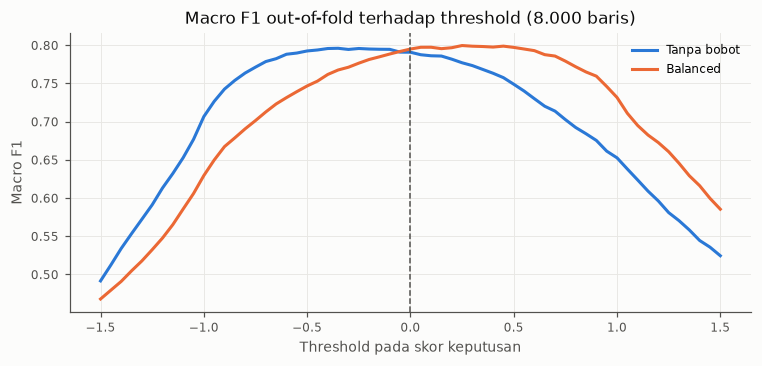

,macro_f1_t0,threshold_terbaik,macro_f1_terbaik
konfigurasi,,,
Tanpa bobot,0.7909,-0.35,0.7961
Balanced,0.7951,0.25,0.7997


In [28]:
def oof_scores(class_weight):
    scores = np.zeros(len(X_sel))
    for fit_idx, val_idx in cv.split(X_sel, y_sel):
        model = make_model('engineered', SVC(kernel='rbf', class_weight=class_weight))
        model.fit(X_sel.iloc[fit_idx], y_sel.iloc[fit_idx])
        scores[val_idx] = model.decision_function(X_sel.iloc[val_idx])
    return scores

X_sel, _, y_sel, _ = train_test_split(
    X_dev, y_dev, train_size=8000, stratify=y_dev, random_state=CFG.SEED
)
thresholds = np.linspace(-1.5, 1.5, 61)

fig, ax = plt.subplots(figsize=(7, 3.4))
rows = []
for label, weight, color in [('Tanpa bobot', None, CFG.NEG_COLOR), ('Balanced', 'balanced', CFG.POS_COLOR)]:
    scores = oof_scores(weight)
    curve_f1 = np.array([f1_score(y_sel, scores > t, average='macro') for t in thresholds])
    best = int(curve_f1.argmax())
    ax.plot(thresholds, curve_f1, color=color, linewidth=2, label=label)
    rows.append({
        'konfigurasi': label,
        'macro_f1_t0': f1_score(y_sel, scores > 0, average='macro'),
        'threshold_terbaik': thresholds[best],
        'macro_f1_terbaik': curve_f1[best],
    })
ax.axvline(0, color=CFG.MUTED, linewidth=1, linestyle='--')
ax.set_title('Macro F1 out-of-fold terhadap threshold (8.000 baris)')
ax.set_xlabel('Threshold pada skor keputusan')
ax.set_ylabel('Macro F1')
ax.legend()
save_fig('threshold_macro_f1')

pd.DataFrame(rows).set_index('konfigurasi').round(4)

#### Insights

> Pergeseran threshold hanya menambah sekitar 0,005 Macro F1 (0,7909 ke 0,7961 tanpa bobot dan 0,7951 ke 0,7997 dengan balanced). Angka terbaik dipilih pada data yang sama, sehingga sedikit optimistis. Tanpa bobot, threshold terbaik negatif (-0,35), yang berarti model lebih diuntungkan bila lebih mudah memprediksi batal, konsisten dengan arah pembobotan kelas.

> Bobot kelas dan threshold mengoreksi masalah yang sama, sehingga keuntungannya tidak bertambah penuh. Keduanya dipilih melalui validasi silang saat tuning, dan kenaikan terbesar diperkirakan datang dari `C`, `gamma`, serta jumlah data.

---

# Kesimpulan dan Rekomendasi <a name="10"></a>

---

## Ringkasan Temuan

Data bersih secara struktur, tetapi 39,2% baris memiliki nilai kosong. Sinyal terkuat berasal dari lead time, periode kedatangan dan pemesanan, permintaan khusus, serta kanal pemesanan. Banyak hubungan bersifat nonlinear dan saling berinteraksi. Train dan test berasal dari distribusi yang sama, sehingga validasi silang berstrata dapat dipercaya untuk Kaggle.

## Rekomendasi Preprocessing

Seluruh langkah dipelajari dari data latih, lalu diterapkan pada validasi dan test tanpa menggabungkan keduanya.

| Langkah | Keputusan | Bukti |
|---|---|---|
| Duplikat | Buang 64 baris identik pada train, test tidak disentuh | Bagian 3 |
| Nilai kosong numerik | Imputasi median | 7 dari 8 kolom tidak terkait target |
| `special_requests` | Imputasi 0 dan tambah penanda kosong | Kekosongan condong ke nol |
| `nightly_rate_idr` | Imputasi median per kanal, tambah penanda tarif nol | Median Complimentary 0 |
| Kategorikal | One-hot, kategori `kosong`, gabungkan kategori langka | Full Board dan Type E |
| Anomali | Pertahankan, pangkas hanya outlier ekstrem | Informatif dan muncul pada test |
| Fitur waktu | `arrival_ym` dan `booking_ym` sebagai kategori | Bagian 6 dan 7 |
| Fitur turunan | `total_nights`, log lead time | Set `engineered` lebih baik |
| Fitur miring | Log atau pangkas riwayat tamu | Skew di atas 20 |
| Scaling | Standardisasi wajib | ROC-AUC 0,5548 tanpa scaling |
| PCA | Hanya untuk visualisasi bonus | ROC-AUC 2D 0,693 |

## Rekomendasi SVM

1. Solver memakai SMO dengan cache baris kernel, dilatih pada seluruh data latih.
2. Ketiga kernel diimplementasikan, dan polynomial serta Gaussian menjadi kandidat utama.
3. Parameter `C`, `gamma`, dan `degree` dituning untuk Macro F1 dengan Stratified K-Fold.
4. Bobot kelas dan threshold dipilih untuk Macro F1, dan `class_weight` juga melayani bonus cost-sensitive.
5. `sklearn.svm.SVC` pada bagian ini menjadi acuan kebenaran implementasi from scratch.

## Keterbatasan

1. Deskripsi resmi fitur belum dicocokkan dengan tab Data pada Kaggle.
2. Hyperparameter pada uji SVM masih bawaan, sehingga skor bersifat arahan.
3. Fitur periode efektif untuk test Kaggle, tetapi tidak berlaku untuk bulan baru pada penerapan nyata. Evaluasi berbasis waktu diperlukan bila sistem benar-benar digunakan.